# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Đọc `README.md` và `GUIDE.md` trước. Notebook này chỉ là **khung**: bạn tự viết mã theo pseudo code trong GUIDE.

## 0. Môi trường (Colab T4)

In [19]:
import os
from google.colab import drive, userdata

drive.mount('/content/drive')
GH_USER, GH_REPO = "DuyNguyen6868", "K4-Track-4-Day10-VisionLanguageModel"
os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
os.environ["GITHUB_TOKEN"] = userdata.get("GITHUB_TOKEN")

!nvidia-smi -L
%cd /content
!test -d {GH_REPO} || git clone https://github.com/DuyNguyen6868/K4-Track-4-Day10-VisionLanguageModel.git
%cd /content/{GH_REPO}
!git config user.name "Nguyễn Cảnh Duy"
!git config user.email "canhduy68kx@gmail.com"
# token chỉ nằm trong .git/config của runtime Colab (không commit); đừng in ra
!git remote set-url origin https://$GITHUB_TOKEN@github.com/DuyNguyen6868/K4-Track-4-Day10-VisionLanguageModel.git
!git pull origin main
# work/ -> Drive: adapter và dự đoán sống sót qua các lần ngắt session
!mkdir -p /content/drive/MyDrive/lab_day10/work && ln -sfn /content/drive/MyDrive/lab_day10/work work
!ls -la work | head -3

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/bin/bash: line 1: nvidia-smi: command not found
/content
/content/K4-Track-4-Day10-VisionLanguageModel
From https://github.com/DuyNguyen6868/K4-Track-4-Day10-VisionLanguageModel
 * branch            main       -> FETCH_HEAD
Already up to date.
lrwxrwxrwx 1 root root 37 Oct 14 03:24 work -> /content/drive/MyDrive/lab_day10/work


In [20]:
!pip -q install -r requirements-colab.txt
!python scripts/prepare_data.py --kaggle --work /content/raw
!ls data/splits   # phải thấy train.jsonl val.jsonl test.jsonl meta.json


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 51.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 34.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 889.0/889.0 kB 37.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 20.2 MB/s eta 0:00:00
Dataset URL: https://www.kaggle.com/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes
License(s): MIT
100% 185M/185M [00:00<00:00, 253MB/s]

dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}
meta.json  test.jsonl  train.jsonl  val.jsonl


In [2]:
!git remote set-url origin https://github.com/{GH_USER}/{GH_REPO}.git
!git pull origin main

From https://github.com/DuyNguyen6868/K4-Track-4-Day10-VisionLanguageModel
 * branch            main       -> FETCH_HEAD
Already up to date.


In [ ]:
# Runtime → Change runtime type → T4 GPU
!nvidia-smi -L
!pip -q install -r requirements-colab.txt

In [ ]:
# Kaggle: dùng Colab Secrets (KAGGLE_USERNAME, KAGGLE_KEY). KHÔNG viết khoá vào notebook.
import os
from google.colab import userdata
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

## 1. Dữ liệu: tải và chia split

In [3]:
!pip -q install -r requirements-colab.txt
!python scripts/prepare_data.py --kaggle --work /content/raw
!python -m pytest -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 39.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 54.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 889.0/889.0 kB 60.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 17.9 MB/s eta 0:00:00
Dataset URL: https://www.kaggle.com/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes
License(s): MIT
100% 185M/185M [00:10<00:00, 17.7MB/s]

dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}
...........................s.........................................    [100%]
68 passed, 1 skipped in 0.35s


In [ ]:
!python scripts/prepare_data.py --kaggle

In [ ]:
# YOUR CODE HERE: đọc data/splits/train.jsonl, xem vài mẫu, vẽ box lên ảnh

In [4]:
import subprocess
def push(msg):
    for cmd in (["git", "add", "-A"], ["git", "commit", "-m", msg], ["git", "push", "origin", "HEAD:main"]):
        r = subprocess.run(cmd, capture_output=True, text=True)
        print(r.stdout + r.stderr)

In [8]:
import json
from PIL import Image

def load_split(name):          # bước 2 sẽ có bản chính thức trong labsrc/data.py
    with open(f"data/splits/{name}.jsonl", encoding="utf-8") as f:
        return [json.loads(l) for l in f if l.strip()]

def load_image(e):
    return Image.open(f"data/{e['image_path']}").convert("RGB")

meta = json.load(open("data/splits/meta.json"))
print("dataset_version:", meta["dataset_version"])
sess = {s: {e["session"] for e in load_split(s)} for s in ("train", "val", "test")}
print({s: len(v) for s, v in sess.items()}, "phiên mỗi split")
assert not (sess["train"] & sess["val"] or sess["train"] & sess["test"] or sess["val"] & sess["test"]), "rò rỉ phiên!"
for s, c in meta["counts"].items():
    print(s, c["images"], "ảnh", c["boxes"])

dataset_version: d10-21e4070301
{'train': 13, 'val': 2, 'test': 3} phiên mỗi split
train 1422 ảnh {'pothole': 1074, 'crack': 1750, 'manhole': 691}
val 276 ảnh {'pothole': 66, 'crack': 470, 'manhole': 103}
test 311 ảnh {'pothole': 121, 'crack': 299, 'manhole': 163}


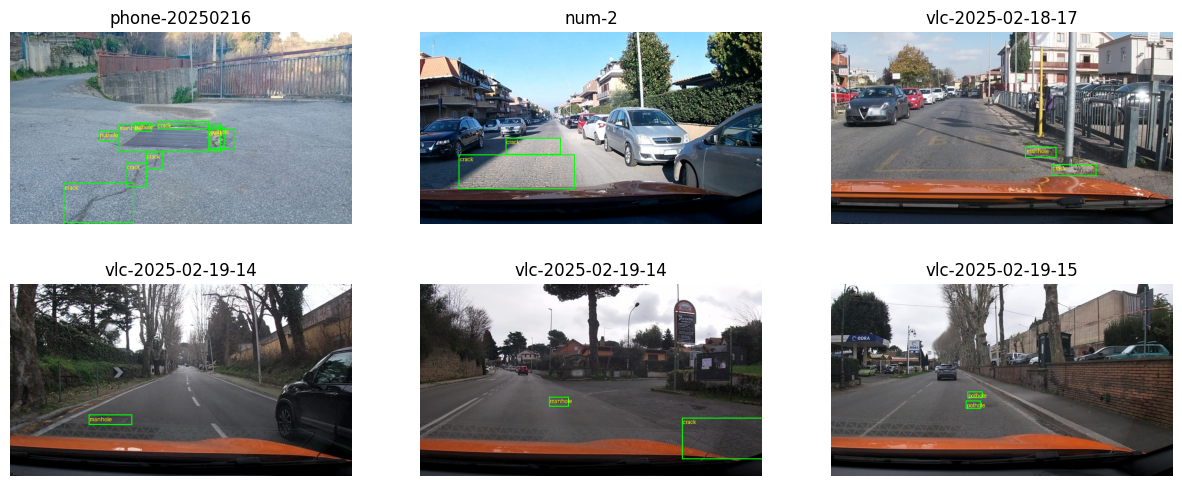

In [9]:
import matplotlib.pyplot as plt
from PIL import ImageDraw
rows = load_split("train")[::200][:6]
fig, ax = plt.subplots(2, 3, figsize=(15, 6))
for a, e in zip(ax.ravel(), rows):
    im = load_image(e); d = ImageDraw.Draw(im)
    for o in e["objects"]:
        xc, yc, w, h = o["yolo"]
        d.rectangle([(xc-w/2)*640, (yc-h/2)*360, (xc+w/2)*640, (yc+h/2)*360], outline="lime", width=2)
        d.text(((xc-w/2)*640+2, (yc-h/2)*360+2), o["label"], fill="yellow")
    a.imshow(im); a.set_title(e["session"]); a.axis("off")
plt.show()

## 2. Nhãn: YOLO → JSON thang 0–1000

In [10]:
!mkdir -p labsrc my_tests report/figures && touch labsrc/__init__.py

In [11]:
%%writefile labsrc/data.py
"""Nhãn, prompt và đọc split (không phụ thuộc torch)."""
import json
import random
from pathlib import Path

from PIL import Image

DATA = Path("data")
CLASSES = ("pothole", "crack", "manhole")


def read_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def load_split(name, limit=None, fraction=1.0, seed=42):
    rows = read_jsonl(DATA / "splits" / f"{name}.jsonl")
    if fraction < 1.0:
        rows = random.Random(seed).sample(rows, int(len(rows) * fraction))
    return rows[:limit] if limit else rows


def load_image(entry):
    return Image.open(DATA / entry["image_path"]).convert("RGB")


def make_prompt(coord="norm1000", width=640, height=360):
    if coord == "norm1000":
        scale = ("Coordinates are integers on a 0-1000 scale relative to the image width and height "
                 "((0,0) = top-left, (1000,1000) = bottom-right).")
    else:
        scale = (f"Coordinates are integer pixels of the {width}x{height} image "
                 f"(x in 0-{width}, y in 0-{height}).")
    return ("Detect all road damage in this dashcam image. Classes: pothole, crack, manhole. "
            'Answer with ONLY a JSON list, no other text: [{"label": "<class>", "bbox_2d": [x1, y1, x2, y2]}]. '
            f"{scale} Answer [] if there is no damage.")


def yolo_to_box(label, yolo, coord="norm1000", width=640, height=360):
    sx, sy = (1000, 1000) if coord == "norm1000" else (width, height)
    xc, yc, w, h = yolo

    def clamp(v, hi):
        return int(min(max(round(v), 0), hi))

    x1, y1 = clamp((xc - w / 2) * sx, sx), clamp((yc - h / 2) * sy, sy)
    x2, y2 = clamp((xc + w / 2) * sx, sx), clamp((yc + h / 2) * sy, sy)
    # box suy biến (x2 <= x1) bị score.py coi là JSON hỏng, nên ép tối thiểu 1 đơn vị
    return {"label": label, "bbox_2d": [x1, y1, max(x2, x1 + 1), max(y2, y1 + 1)]}


def objects_to_answer(objects, coord="norm1000", width=640, height=360):
    boxes = [yolo_to_box(o["label"], o["yolo"], coord, width, height) for o in objects]
    boxes.sort(key=lambda b: (b["bbox_2d"][1], b["bbox_2d"][0]))  # trên→dưới, trái→phải
    return json.dumps(boxes, separators=(",", ":"))

Writing labsrc/data.py


In [12]:
from labsrc.data import *
from scripts.score import _gt_boxes, parse_output

bad = 0
for e in load_split("train"):
    ans = objects_to_answer(e["objects"], width=e["width"], height=e["height"])
    gt = sorted(v for g in _gt_boxes(e) for v in g["bbox"])
    pr = sorted(v for p in parse_output(ans) for v in p["bbox"])
    bad += len(gt) != len(pr) or max((abs(a - b) for a, b in zip(gt, pr)), default=0) > 1.5
print("ảnh lệch > 1.5 đơn vị:", bad, "/ 1422 (chỉ nên là vài ảnh có box chạm mép)")

e = next(x for x in load_split("train") if len(x["objects"]) >= 2)
print(objects_to_answer(e["objects"], width=e["width"], height=e["height"]))

ảnh lệch > 1.5 đơn vị: 32 / 1422 (chỉ nên là vài ảnh có box chạm mép)
[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]


In [ ]:
# YOUR CODE HERE: viết yolo_to_box() và objects_to_answer() (GUIDE bước 2)

## 3. E0: zero-shot

In [ ]:
# YOUR CODE HERE: nạp model 4-bit, suy luận trên test → work/e0.jsonl (GUIDE bước 3)

In [25]:
%%writefile labsrc/modeling.py
"""Nạp model 4-bit, mã hoá ví dụ + mask loss, setup LoRA, suy luận."""
import json
import re
from pathlib import Path

import torch
from peft import LoraConfig, get_peft_model
from transformers import AutoProcessor, BitsAndBytesConfig, Qwen3VLForConditionalGeneration

from .data import load_image

MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"
PROJ_KEYS = ("visual.merger", "visual.deepstack_merger_list")
LLM_RE = r"model\.language_model\.layers\.\d+\.(self_attn\.(q|k|v|o)_proj|mlp\.(gate|up|down)_proj)"
VIT_RE = r"model\.visual\.blocks\.\d+\.(attn\.(qkv|proj)|mlp\.(linear_fc1|linear_fc2))"


def load_model():
    quant = BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True, llm_int8_skip_modules=["visual", "lm_head"])
    model = Qwen3VLForConditionalGeneration.from_pretrained(
        MODEL_ID, quantization_config=quant, dtype=torch.float16, device_map={"": 0})
    processor = AutoProcessor.from_pretrained(MODEL_ID)
    processor.tokenizer.padding_side = "left"
    return model, processor


def user_msg(image, prompt):
    return {"role": "user", "content": [{"type": "image", "image": image},
                                        {"type": "text", "text": prompt}]}


# ---------- Bước 4: ví dụ huấn luyện + mask loss ----------
def encode_example(processor, image, prompt, answer):
    kw = dict(tokenize=True, return_dict=True, return_tensors="pt")
    user = user_msg(image, prompt)
    assistant = {"role": "assistant", "content": [{"type": "text", "text": answer}]}
    prompt_enc = processor.apply_chat_template([user], add_generation_prompt=True, **kw)
    full_enc = processor.apply_chat_template([user, assistant], add_generation_prompt=False, **kw)
    n = prompt_enc["input_ids"].shape[1]
    assert torch.equal(full_enc["input_ids"][0, :n], prompt_enc["input_ids"][0]), "prompt không là tiền tố"
    labels = full_enc["input_ids"].clone()
    labels[:, :n] = -100                       # chỉ học phần trả lời
    out = dict(full_enc)
    out["labels"] = labels
    return out


def collate(batch, pad_id):
    out = {}
    for k in batch[0]:
        if k in ("pixel_values", "image_grid_thw"):          # nối, KHÔNG pad
            out[k] = torch.cat([b[k] for b in batch], 0)
        else:                                                # pad phải đến cùng độ dài
            fill = {"input_ids": pad_id, "labels": -100}.get(k, 0)
            width = max(b[k].shape[1] for b in batch)
            out[k] = torch.cat([torch.nn.functional.pad(b[k], (0, width - b[k].shape[1]), value=fill)
                                for b in batch], 0)
    return out


# ---------- Bước 5: setup LoRA / đóng băng ----------
def apply_setup(model, cfg):
    for p in model.parameters():
        p.requires_grad = False
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    model.enable_input_require_grads()
    model.config.use_cache = False
    regex = LLM_RE if cfg["lora"]["targets"] == "llm" else f"{LLM_RE}|{VIT_RE}"
    matched = [n for n, _ in model.named_modules() if re.fullmatch(regex, n)]
    lora = LoraConfig(r=cfg["lora"]["r"], lora_alpha=cfg["lora"]["alpha"],
                      lora_dropout=cfg["lora"]["dropout"], target_modules=regex)
    model = get_peft_model(model, lora)
    if cfg["train_projector"]:
        for n, p in model.named_parameters():
            if any(k in n for k in PROJ_KEYS):
                p.data = p.data.float()
                p.requires_grad = True
    for p in model.parameters():               # GradScaler cần gradient fp32
        if p.requires_grad and p.dtype != torch.float32:
            p.data = p.data.float()
    return model, len(matched)


def projector_state(model):
    return {n: p.detach().cpu() for n, p in model.named_parameters()
            if any(k in n for k in PROJ_KEYS)}


def load_projector_state(model, state):
    params = dict(model.named_parameters())
    with torch.no_grad():
        for n, v in state.items():
            params[n].copy_(v)                 # fp32 → fp16 (KeyError nếu tên không khớp)
    return len(state)


# ---------- Bước 3/7: suy luận ----------
def run_inference(model, processor, entries, prompt, out_path, batch_size=4, max_new_tokens=256):
    out_path = Path(out_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    done = set()
    if out_path.exists():                      # chạy tiếp được sau khi Colab ngắt
        done = {json.loads(ln)["image_id"] for ln in out_path.read_text(encoding="utf-8").splitlines()
                if ln.strip()}
    todo = [e for e in entries if e["image_id"] not in done]
    model.eval()
    with open(out_path, "a", encoding="utf-8") as f:
        for i in range(0, len(todo), batch_size):
            chunk = todo[i:i + batch_size]
            messages = [[user_msg(load_image(e), prompt)] for e in chunk]
            inputs = processor.apply_chat_template(
                messages, tokenize=True, add_generation_prompt=True, return_dict=True,
                return_tensors="pt", padding=True).to("cuda")
            with torch.inference_mode():
                out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
            raws = processor.batch_decode(out[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)
            for e, raw in zip(chunk, raws):
                f.write(json.dumps({"image_id": e["image_id"], "raw": raw}, ensure_ascii=False) + "\n")
            f.flush()
            print(f"{len(done) + i + len(chunk)}/{len(entries)}", end="\r")
    print()

Overwriting labsrc/modeling.py


In [38]:
%%writefile labsrc/modeling.py
"""Nạp model 4-bit, mã hoá ví dụ + mask loss, setup LoRA, suy luận."""
import json
import re
from pathlib import Path

import torch
from peft import LoraConfig, get_peft_model
from transformers import AutoProcessor, BitsAndBytesConfig, Qwen3VLForConditionalGeneration

from .data import load_image

MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"
PROJ_KEYS = ("visual.merger", "visual.deepstack_merger_list")
LLM_RE = r"model\.language_model\.layers\.\d+\.(self_attn\.(q|k|v|o)_proj|mlp\.(gate|up|down)_proj)"
VIT_RE = r"model\.visual\.blocks\.\d+\.(attn\.(qkv|proj)|mlp\.(linear_fc1|linear_fc2))"


# "visual" một mình KHÔNG đủ trên transformers 5.19: merger/deepstack vẫn bị nén 4-bit (đã đo),
# nên liệt kê cả tên đầy đủ có tiền tố "model."
SKIP_QUANT = ["visual", "model.visual", "visual.merger", "visual.deepstack_merger_list", "lm_head"]


def assert_vit_not_quantized(model):
    import bitsandbytes as bnb
    bad = [n for n, m in model.named_modules()
           if isinstance(m, bnb.nn.Linear4bit) and "visual" in n.split(".")]
    assert not bad, f"{len(bad)} Linear trong ViT vẫn bị lượng tử hoá 4-bit, ví dụ: {bad[:3]}"


def load_model():
    quant = BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True, llm_int8_skip_modules=SKIP_QUANT)
    model = Qwen3VLForConditionalGeneration.from_pretrained(
        MODEL_ID, quantization_config=quant, dtype=torch.float16, device_map={"": 0})
    assert_vit_not_quantized(model)
    processor = AutoProcessor.from_pretrained(MODEL_ID)
    processor.tokenizer.padding_side = "left"
    return model, processor


def user_msg(image, prompt):
    return {"role": "user", "content": [{"type": "image", "image": image},
                                        {"type": "text", "text": prompt}]}


# ---------- Bước 4: ví dụ huấn luyện + mask loss ----------
def encode_example(processor, image, prompt, answer):
    kw = dict(tokenize=True, return_dict=True, return_tensors="pt")
    user = user_msg(image, prompt)
    assistant = {"role": "assistant", "content": [{"type": "text", "text": answer}]}
    prompt_enc = processor.apply_chat_template([user], add_generation_prompt=True, **kw)
    full_enc = processor.apply_chat_template([user, assistant], add_generation_prompt=False, **kw)
    n = prompt_enc["input_ids"].shape[1]
    assert torch.equal(full_enc["input_ids"][0, :n], prompt_enc["input_ids"][0]), "prompt không là tiền tố"
    labels = full_enc["input_ids"].clone()
    labels[:, :n] = -100                       # chỉ học phần trả lời
    out = dict(full_enc)
    out["labels"] = labels
    return out


def collate(batch, pad_id):
    out = {}
    for k in batch[0]:
        if k in ("pixel_values", "image_grid_thw"):          # nối, KHÔNG pad
            out[k] = torch.cat([b[k] for b in batch], 0)
        else:                                                # pad phải đến cùng độ dài
            fill = {"input_ids": pad_id, "labels": -100}.get(k, 0)
            width = max(b[k].shape[1] for b in batch)
            out[k] = torch.cat([torch.nn.functional.pad(b[k], (0, width - b[k].shape[1]), value=fill)
                                for b in batch], 0)
    return out


# ---------- Bước 5: setup LoRA / đóng băng ----------
def apply_setup(model, cfg):
    for p in model.parameters():
        p.requires_grad = False
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    model.enable_input_require_grads()
    model.config.use_cache = False
    regex = LLM_RE if cfg["lora"]["targets"] == "llm" else f"{LLM_RE}|{VIT_RE}"
    matched = [n for n, _ in model.named_modules() if re.fullmatch(regex, n)]
    lora = LoraConfig(r=cfg["lora"]["r"], lora_alpha=cfg["lora"]["alpha"],
                      lora_dropout=cfg["lora"]["dropout"], target_modules=regex)
    model = get_peft_model(model, lora)
    if cfg["train_projector"]:
        for n, p in model.named_parameters():
            if any(k in n for k in PROJ_KEYS):
                p.data = p.data.float()
                p.requires_grad = True
    for p in model.parameters():               # GradScaler cần gradient fp32
        if p.requires_grad and p.dtype != torch.float32:
            p.data = p.data.float()
    return model, len(matched)


def projector_state(model):
    return {n: p.detach().cpu() for n, p in model.named_parameters()
            if any(k in n for k in PROJ_KEYS)}


def load_projector_state(model, state):
    params = dict(model.named_parameters())
    with torch.no_grad():
        for n, v in state.items():
            params[n].copy_(v)                 # fp32 → fp16 (KeyError nếu tên không khớp)
    return len(state)


# ---------- Bước 3/7: suy luận ----------
def run_inference(model, processor, entries, prompt, out_path, batch_size=4, max_new_tokens=256):
    out_path = Path(out_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    done = set()
    if out_path.exists():                      # chạy tiếp được sau khi Colab ngắt
        done = {json.loads(ln)["image_id"] for ln in out_path.read_text(encoding="utf-8").splitlines()
                if ln.strip()}
    todo = [e for e in entries if e["image_id"] not in done]
    model.eval()
    with open(out_path, "a", encoding="utf-8") as f:
        for i in range(0, len(todo), batch_size):
            chunk = todo[i:i + batch_size]
            messages = [[user_msg(load_image(e), prompt)] for e in chunk]
            inputs = processor.apply_chat_template(
                messages, tokenize=True, add_generation_prompt=True, return_dict=True,
                return_tensors="pt", padding=True).to("cuda")
            with torch.inference_mode():
                out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
            raws = processor.batch_decode(out[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)
            for e, raw in zip(chunk, raws):
                f.write(json.dumps({"image_id": e["image_id"], "raw": raw}, ensure_ascii=False) + "\n")
            f.flush()
            print(f"{len(done) + i + len(chunk)}/{len(entries)}", end="\r")
    print()

Overwriting labsrc/modeling.py


In [26]:
%%writefile labsrc/infer.py
"""Bước 3/7: suy luận. E0: bỏ --adapter. Ví dụ: python -m labsrc.infer --adapter work/adapters/e1 --out work/e1.jsonl"""
import argparse
import json
from pathlib import Path

import torch
from peft import PeftModel

from .data import load_split, make_prompt
from .modeling import load_model, load_projector_state, run_inference


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--adapter")
    ap.add_argument("--out", required=True)
    ap.add_argument("--split", default="test", choices=["val", "test"])
    ap.add_argument("--limit", type=int)
    ap.add_argument("--coord", choices=["norm1000", "pixel"])    # mặc định: lấy từ run.json của adapter
    ap.add_argument("--bs", type=int, default=4)
    ap.add_argument("--max-new-tokens", type=int, default=256)
    args = ap.parse_args()

    adapter = Path(args.adapter) if args.adapter else None
    coord = args.coord
    if adapter and not coord and (adapter / "run.json").exists():
        coord = json.loads((adapter / "run.json").read_text(encoding="utf-8")).get("coord")
    coord = coord or "norm1000"
    print(f"coord={coord}")

    model, processor = load_model()
    if adapter:
        model = PeftModel.from_pretrained(model, str(adapter))
        extra = adapter / "extra_trainable.pt"
        if extra.exists():
            n = load_projector_state(model, torch.load(extra, map_location="cpu"))
            print(f"đã nạp lại {n} tensor projector từ {extra}")
    run_inference(model, processor, load_split(args.split, args.limit), make_prompt(coord), args.out,
                  batch_size=args.bs, max_new_tokens=args.max_new_tokens)


if __name__ == "__main__":
    main()

Writing labsrc/infer.py


In [14]:
%%writefile labsrc/viz.py
"""Vẽ box đúng (xanh) và box dự đoán (đỏ) để làm ảnh minh hoạ cho báo cáo."""
from pathlib import Path

from PIL import Image, ImageDraw

from scripts.score import _gt_boxes, _match, _to_norm1000, parse_output

from .data import DATA, read_jsonl


def image_errors(entry, raw, coord="norm1000"):
    parsed = parse_output(raw)
    pred = _to_norm1000(parsed, coord, entry["width"], entry["height"]) if parsed else []
    per, _ = _match(_gt_boxes(entry), pred)
    return (sum(v[0] for v in per.values()), sum(v[1] for v in per.values()),
            sum(v[2] for v in per.values()))          # tp, fp, fn


def draw(entry, raw, path, title, coord="norm1000", zoom=2):
    img = Image.open(DATA / entry["image_path"]).convert("RGB")
    img = img.resize((img.width * zoom, img.height * zoom))
    d = ImageDraw.Draw(img)
    for g in _gt_boxes(entry):
        x1, y1, x2, y2 = g["bbox"]
        d.rectangle([x1 * img.width / 1000, y1 * img.height / 1000,
                     x2 * img.width / 1000, y2 * img.height / 1000], outline=(0, 200, 0), width=3)
        d.text((x1 * img.width / 1000 + 3, y1 * img.height / 1000 + 2), g["label"], fill=(0, 255, 0))
    for p in parse_output(raw) or []:
        x1, y1, x2, y2 = p["bbox"]
        sx, sy = (img.width / 1000, img.height / 1000) if coord == "norm1000" else (zoom, zoom)
        d.rectangle([x1 * sx, y1 * sy, x2 * sx, y2 * sy], outline=(230, 0, 0), width=2)
        d.text((x1 * sx + 3, y2 * sy - 12), p["label"], fill=(255, 80, 80))
    d.rectangle([0, 0, img.width, 16], fill=(0, 0, 0))
    d.text((4, 2), title, fill=(255, 255, 255))
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    img.save(path)


def make_figures(pred_path, split="test", coord="norm1000", out_dir="report/figures", name="e1", k=3):
    entries = {e["image_id"]: e for e in read_jsonl(DATA / "splits" / f"{split}.jsonl")}
    preds = {r["image_id"]: r["raw"] for r in read_jsonl(pred_path)}
    scored = [(image_errors(entries[i], preds[i], coord), i) for i in preds]
    good = [i for (tp, fp, fn), i in scored if tp > 0 and fp == 0 and fn == 0][:k]
    bad = [i for (tp, fp, fn), i in sorted(scored, key=lambda s: -(s[0][1] + s[0][2]))][:k]
    for tag, ids in (("right", good), ("wrong", bad)):
        for i in ids:
            tp, fp, fn = image_errors(entries[i], preds[i], coord)
            draw(entries[i], preds[i], f"{out_dir}/{name}_{tag}_{i}.png",
                 f"{name} {tag} | TP={tp} FP={fp} FN={fn} | green=GT, red=pred", coord)
    print(f"đã lưu {len(good)} ảnh đúng + {len(bad)} ảnh sai vào {out_dir}/")

Writing labsrc/viz.py


In [15]:
%%writefile labsrc/count_params.py
"""Bước 5 (không cần GPU, không tải trọng số): đếm tham số từng khối và kiểm tra regex LoRA."""
import re

import torch
from transformers import AutoConfig, Qwen3VLForConditionalGeneration

from .modeling import LLM_RE, MODEL_ID, VIT_RE

cfg = AutoConfig.from_pretrained(MODEL_ID)
with torch.device("meta"):                      # dựng khung model rỗng, không tốn RAM/VRAM
    m = Qwen3VLForConditionalGeneration._from_config(cfg)


def count(mod):
    return sum(p.numel() for p in mod.parameters())


vis = m.model.visual
print(f"tổng              : {count(m):>15,}")
print(f"language_model    : {count(m.model.language_model):>15,}")
print(f"visual (ViT+merger): {count(vis):>14,}")
print(f"  visual.blocks   : {count(vis.blocks):>15,}")
print(f"  visual.merger   : {count(vis.merger):>15,}")
print(f"  deepstack_merger: {count(vis.deepstack_merger_list):>15,}")
names = [n for n, _ in m.named_modules()]
print("module khớp LLM_RE:", sum(bool(re.fullmatch(LLM_RE, n)) for n in names), "(mong đợi 252)")
print("module khớp VIT_RE:", sum(bool(re.fullmatch(VIT_RE, n)) for n in names), "(mong đợi 96)")

Writing labsrc/count_params.py


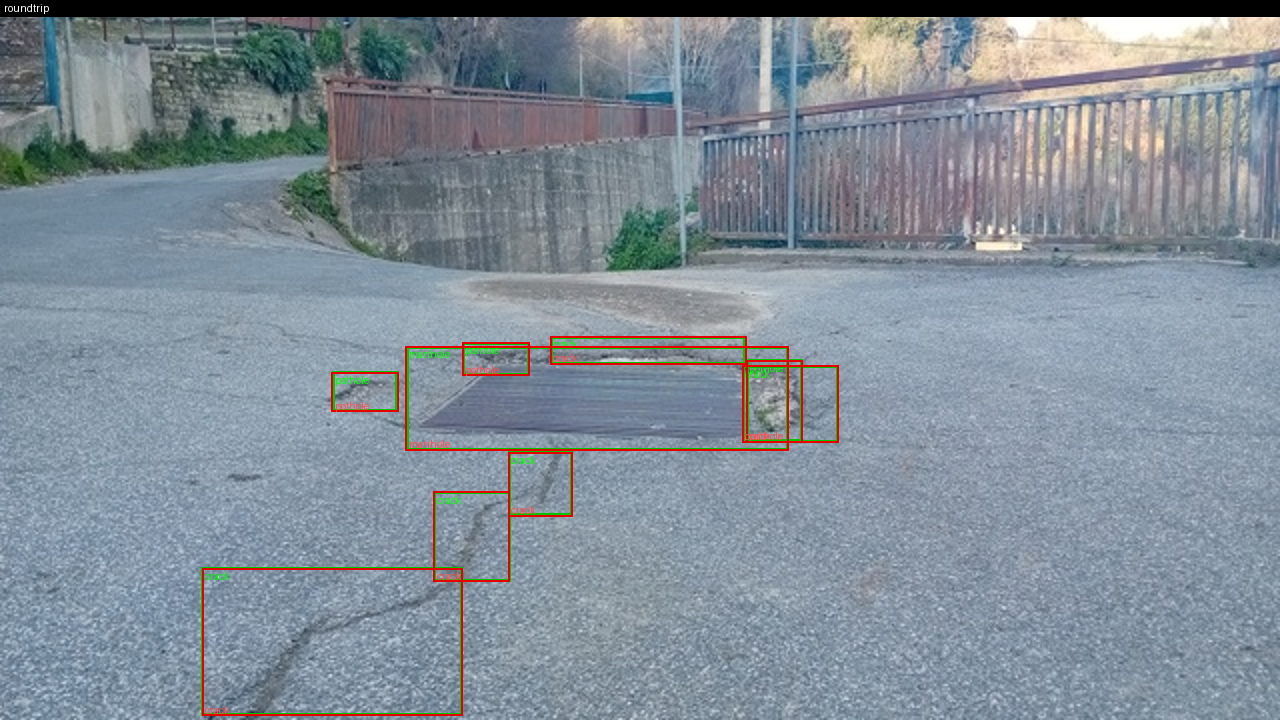

In [16]:
from labsrc.viz import draw
from IPython.display import Image as Show
e = next(x for x in load_split("train") if len(x["objects"]) >= 2)
ans = objects_to_answer(e["objects"], width=e["width"], height=e["height"])
draw(e, ans, "work/roundtrip.png", "roundtrip")
Show("work/roundtrip.png")

In [17]:
!python -m labsrc.count_params

config.json: 100% 1.50k/1.50k [00:00<00:00, 4.10MB/s]
tổng              :   4,437,815,808
language_model    :   4,022,468,096
visual (ViT+merger):    415,347,712
  visual.blocks   :     302,309,376
  visual.merger   :      27,271,680
  deepstack_merger:      81,833,472
module khớp LLM_RE: 252 (mong đợi 252)
module khớp VIT_RE: 96 (mong đợi 96)


In [24]:
!pwd
!ls labsrc


/content/K4-Track-4-Day10-VisionLanguageModel
count_params.py  data.py  __init__.py  modeling.py  __pycache__  viz.py


In [28]:
!python -m labsrc.infer --split val --limit 40 --out work/dbg_e0_val40.jsonl

coord=norm1000
model.safetensors.index.json: 100% 64.7k/64.7k [00:00<00:00, 131MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0% 0/2 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/8.88G [00:00<?, ?B/s]         
Reconstructing (incomplete total...):   9% 805M/8.88G [00:07<01:18, 103MB/s,  167MB/s  ]
Reconstructing (incomplete total...):  45% 3.96G/8.88G [00:59<02:04, 39.6MB/s, 39.6MB/s  ]
Reconstructing (incomplete total...):  52% 4.63G/8.88G [01:49<03:50, 18.4MB/s, 18.4MB/s  ]
Reconstructing (incomplete total...):  57% 5.10G/8.88G [02:29<04:35, 13.7MB/s, 13.7MB/s  ]
Reconstructing (incomplete total...):  76% 6.78G/8.88G [02:49<02:38, 13.2MB/s, 13.2MB/s  ]
Reconstructing (incomplete total...):  82% 7.25G/8.88G [02:59<00:46, 35.2MB/s, 13.2MB/s  ]
Reconstructing (incomplete total...):  82% 7.25G/8.88G [03:09<00:46, 35.2MB/s, 35.2MB/s  ]
Reconstructing (incomplete total...):  91% 8.07G/8.88G [03:22<00:23, 35.0MB/s

In [29]:
import json
for ln in open("work/dbg_e0_val40.jsonl").readlines()[:5]:
    r = json.loads(ln); print(r["image_id"], "->", repr(r["raw"][:300]), "\n")

vlcsnap-2025-02-18-18h30m17s408 -> '[{"label": "crack", "bbox_2d": [0, 377, 600, 700]}]' 

vlcsnap-2025-02-18-18h30m20s293 -> '[{"label": "crack", "bbox_2d": [0, 604, 1000, 750]}]' 

vlcsnap-2025-02-18-18h30m22s081 -> '[{"label": "crack", "bbox_2d": [0, 500, 600, 600]}]' 

vlcsnap-2025-02-18-18h30m24s122 -> '[{"label": "crack", "bbox_2d": [0, 500, 1000, 750]}]' 

vlcsnap-2025-02-18-18h30m25s530 -> '[{"label": "manhole", "bbox_2d": [609, 519, 675, 546]}]' 



In [30]:
import os, shutil
os.makedirs("work/val40", exist_ok=True)
with open("work/val40/val.jsonl", "w", encoding="utf-8") as f:
    for e in load_split("val", 40): f.write(json.dumps(e, ensure_ascii=False) + "\n")
shutil.copy("data/splits/meta.json", "work/val40/meta.json")
!python scripts/score.py --split val --splits-dir work/val40 --pred work/dbg_e0_val40.jsonl --name dbg --out work/dbg_e0.json

dbg [val] n=40 valid=0.975 P=0.147 R=0.051 F1=0.076 CI95=0.024-0.144 meanIoU=0.592 FP/img=0.72
   pothole  P=0.000 R=0.000 F1=0.000
   crack    P=0.000 R=0.000 F1=0.000
   manhole  P=0.417 R=0.167 F1=0.238


In [31]:
!python -m labsrc.infer --out work/e0.jsonl
!python scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json

coord=norm1000
Loading weights: 100% 713/713 [00:37<00:00, 19.03it/s]
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call_

## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

In [32]:
%%writefile labsrc/train.py
"""Bước 6: vòng huấn luyện. Ví dụ: python -m labsrc.train --config configs/e1.yaml --out work/adapters/e1"""
import argparse
import json
import math
import random
import time
from pathlib import Path

import torch
import yaml
from torch.utils.data import DataLoader, Dataset

from .data import load_image, load_split, make_prompt, objects_to_answer
from .modeling import apply_setup, collate, encode_example, load_model, projector_state


class SFTData(Dataset):
    def __init__(self, entries, processor, coord):
        self.entries, self.processor, self.coord = entries, processor, coord
        self.prompt = make_prompt(coord)

    def __len__(self):
        return len(self.entries)

    def __getitem__(self, i):
        e = self.entries[i]
        answer = objects_to_answer(e["objects"], self.coord, e["width"], e["height"])
        return encode_example(self.processor, load_image(e), self.prompt, answer)


def forever(loader):
    while True:
        yield from loader


def save(model, out, cfg):
    model.save_pretrained(out)                       # chỉ lưu adapter LoRA
    if cfg["train_projector"]:                       # projector nằm NGOÀI adapter → lưu riêng
        torch.save(projector_state(model), out / "extra_trainable.pt")


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--rank", type=int)                  # E4: đổi rank (alpha = 2*r)
    ap.add_argument("--train-fraction", type=float, default=1.0)   # E4: đổi kích thước dữ liệu
    ap.add_argument("--coord", default="norm1000", choices=["norm1000", "pixel"])   # E4: đổi thang
    ap.add_argument("--max-steps", type=int)             # chỉ để chạy thử nhanh
    ap.add_argument("--batch-size", type=int)            # chỉ dùng khi hết VRAM (giữ batch*accum = 8)
    ap.add_argument("--grad-accum", type=int)
    args = ap.parse_args()

    cfg = yaml.safe_load(Path(args.config).read_text(encoding="utf-8"))
    if args.rank:
        cfg["lora"]["r"], cfg["lora"]["alpha"] = args.rank, 2 * args.rank
    cfg["batch_size"] = args.batch_size or cfg["batch_size"]
    cfg["grad_accum"] = args.grad_accum or cfg["grad_accum"]
    max_steps = args.max_steps or cfg["max_steps"]
    out = Path(args.out)
    out.mkdir(parents=True, exist_ok=True)
    random.seed(cfg["seed"])
    torch.manual_seed(cfg["seed"])

    model, processor = load_model()
    model, n_matched = apply_setup(model, cfg)
    params = [p for p in model.parameters() if p.requires_grad]
    n_trainable = sum(p.numel() for p in params)
    print(f"{cfg['name']}: {n_matched} module LoRA, {n_trainable:,} tham số huấn luyện")

    entries = load_split("train", fraction=args.train_fraction, seed=cfg["seed"])
    data = SFTData(entries, processor, args.coord)
    gen = torch.Generator().manual_seed(cfg["seed"])
    loader = DataLoader(data, batch_size=cfg["batch_size"], shuffle=True, drop_last=True, generator=gen,
                        collate_fn=lambda b: collate(b, processor.tokenizer.pad_token_id))
    print(f"{len(entries)} ảnh train, coord={args.coord}")

    opt = torch.optim.AdamW(params, lr=cfg["lr"], weight_decay=0.0)
    warm = max(1, int(0.05 * max_steps))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else
                                              0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, max_steps - warm))))
    scaler = torch.amp.GradScaler("cuda")

    model.train()
    torch.cuda.reset_peak_memory_stats()
    t0, losses, batches = time.time(), [], forever(loader)
    for step in range(1, max_steps + 1):
        step_loss = 0.0
        for _ in range(cfg["grad_accum"]):
            batch = {k: v.to("cuda") for k, v in next(batches).items()}
            with torch.autocast("cuda", dtype=torch.float16):
                loss = model(**batch).loss / cfg["grad_accum"]
            if not torch.isfinite(loss):
                raise RuntimeError(f"loss không hữu hạn ở bước {step}: nguy cơ tràn số fp16")
            scaler.scale(loss).backward()
            step_loss += loss.item()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(params, 1.0)
        scaler.step(opt)
        scaler.update()
        opt.zero_grad(set_to_none=True)
        sched.step()
        losses.append(step_loss)
        if step % 10 == 0 or step == 1:
            print(f"step {step}/{max_steps} loss={step_loss:.4f} lr={sched.get_last_lr()[0]:.2e} "
                  f"{(time.time() - t0) / 60:.1f}ph vram={torch.cuda.max_memory_allocated() / 2**30:.2f}GB",
                  flush=True)
        if step % 100 == 0:
            save(model, out, cfg)

    save(model, out, cfg)
    run = {"name": cfg["name"], "trainable_params": n_trainable, "matched_modules": n_matched,
           "peak_vram_gb": round(torch.cuda.max_memory_allocated() / 2**30, 2),
           "train_minutes": round((time.time() - t0) / 60, 1), "coord": args.coord,
           "train_images": len(entries), "rank": cfg["lora"]["r"], "max_steps": max_steps,
           "batch_size": cfg["batch_size"], "grad_accum": cfg["grad_accum"], "losses": losses}
    (out / "run.json").write_text(json.dumps(run, indent=1), encoding="utf-8")
    print({k: v for k, v in run.items() if k != "losses"})


if __name__ == "__main__":
    main()

Writing labsrc/train.py


In [33]:
%%writefile labsrc/check_encode.py
"""Bước 4 (không cần GPU): kiểm tra số token ảnh và mask loss trên một ví dụ."""
from transformers import AutoProcessor

from .data import load_image, load_split, make_prompt, objects_to_answer
from .modeling import MODEL_ID, encode_example

proc = AutoProcessor.from_pretrained(MODEL_ID)
e = next(x for x in load_split("train") if len(x["objects"]) >= 2)
answer = objects_to_answer(e["objects"], width=e["width"], height=e["height"])
ex = encode_example(proc, load_image(e), make_prompt(), answer)
ids, labels = ex["input_ids"][0], ex["labels"][0]
img_id = proc.tokenizer.convert_tokens_to_ids("<|image_pad|>")
print("các khoá:", list(ex))
print("token ảnh:", int((ids == img_id).sum()), "(mong đợi 220)")
print("tổng token:", len(ids), "| token có loss:", int((labels != -100).sum()))
print("phần có loss:", repr(proc.tokenizer.decode(ids[labels != -100])))
print("đáp án      :", answer)
assert (labels[ids == img_id] == -100).all(), "token ảnh không được có loss"

Writing labsrc/check_encode.py


In [42]:
!python -m labsrc.train --config configs/e3.yaml --out work/adapters/smoke --max-steps 3

Loading weights: 100% 713/713 [00:36<00:00, 19.46it/s]
E3: 348 module LoRA, 148,426,752 tham số huấn luyện
1422 ảnh train, coord=norm1000
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
step 1/3 loss=2.0895 lr=2.00e-04 0.2ph vram=6.35GB
{'name': 'E3', 'trainable_params': 148426752, 'matched_modules': 348, 'peak_vram_gb': 7.46, 'train_minutes': 0.6, 'coord': 'norm1000', 'train_images': 1422, 'rank': 16, 'max_steps': 3, 'batch_size': 2, 'grad_accum': 4}


In [36]:
%%writefile labsrc/debug_dtype.py
"""Chẩn đoán 'Attempting to unscale FP16 gradients' và đếm tham số huấn luyện theo nhóm."""
import collections

import torch
import yaml

from .data import load_image, load_split, make_prompt, objects_to_answer
from .modeling import PROJ_KEYS, apply_setup, collate, encode_example, load_model

cfg = yaml.safe_load(open("configs/e3.yaml", encoding="utf-8"))
model, processor = load_model()
model, n_matched = apply_setup(model, cfg)


def group(name):
    if "lora_" in name:
        return "lora_vit" if ".visual." in name else "lora_llm"
    return next((k for k in PROJ_KEYS if k in name), "khác")


train, frozen = collections.defaultdict(lambda: [0, collections.Counter()]), collections.Counter()
for name, p in model.named_parameters():
    g = group(name)
    if p.requires_grad:
        train[g][0] += p.numel()
        train[g][1][str(p.dtype)] += 1
    elif g in PROJ_KEYS:
        frozen[g] += p.numel()
print("--- tham số ĐANG huấn luyện theo nhóm (số lượng, {dtype: số tensor}) ---")
for g, (num, c) in train.items():
    print(f"{g:30s} {num:>13,} {dict(c)}")
print("--- tham số projector còn BỊ ĐÓNG BĂNG:", dict(frozen))

e = load_split("train")[0]
ans = objects_to_answer(e["objects"], width=e["width"], height=e["height"])
batch = collate([encode_example(processor, load_image(e), make_prompt(), ans)], processor.tokenizer.pad_token_id)
batch = {k: v.to("cuda") for k, v in batch.items()}
model.train()
with torch.autocast("cuda", dtype=torch.float16):
    loss = model(**batch).loss
loss.backward()
bad = [(n, str(p.dtype), str(p.grad.dtype)) for n, p in model.named_parameters()
       if p.grad is not None and p.grad.dtype != torch.float32]
print("tham số có grad không phải fp32:", len(bad))
for x in bad[:10]:
    print("  ", x)
nograd = [n for n, p in model.named_parameters() if p.requires_grad and p.grad is None]
print("requires_grad nhưng không có grad:", len(nograd), nograd[:5])


Writing labsrc/debug_dtype.py


In [44]:
%%writefile labsrc/ugdebug_dtype.py
"""Chẩn đoán dtype/lượng tử hoá của ViT + projector, và lỗi 'Attempting to unscale FP16 gradients'."""
import collections

import torch
import yaml

from .data import load_image, load_split, make_prompt, objects_to_answer
from .modeling import PROJ_KEYS, apply_setup, collate, encode_example, load_model

cfg = yaml.safe_load(open("configs/e3.yaml", encoding="utf-8"))
model, processor = load_model()          # assert_vit_not_quantized chạy trong load_model
inner = model.model
for label, mod in (("visual.blocks[0].attn.qkv", inner.visual.blocks[0].attn.qkv),
                   ("visual.merger.linear_fc1", inner.visual.merger.linear_fc1),
                   ("language_model q_proj", inner.language_model.layers[0].self_attn.q_proj),
                   ("lm_head", model.lm_head)):
    print(f"{label:28s} {type(mod).__name__:12s} weight={mod.weight.dtype} numel={mod.weight.numel():,}")
model, n_matched = apply_setup(model, cfg)


def group(name):
    if "lora_" in name:
        return "lora_vit" if ".visual." in name else "lora_llm"
    return next((k for k in PROJ_KEYS if k in name), "khác")


train, frozen = collections.defaultdict(lambda: [0, collections.Counter()]), collections.Counter()
for name, p in model.named_parameters():
    g = group(name)
    if p.requires_grad:
        train[g][0] += p.numel()
        train[g][1][str(p.dtype)] += 1
    elif g in PROJ_KEYS:
        frozen[g] += p.numel()
print("--- tham số ĐANG huấn luyện theo nhóm (số lượng, {dtype: số tensor}) ---")
for g, (num, c) in train.items():
    print(f"{g:30s} {num:>13,} {dict(c)}")
print("tổng:", sum(v[0] for v in train.values()), "| projector còn bị đóng băng:", dict(frozen))

e = load_split("train")[0]
ans = objects_to_answer(e["objects"], width=e["width"], height=e["height"])
batch = collate([encode_example(processor, load_image(e), make_prompt(), ans)], processor.tokenizer.pad_token_id)
batch = {k: v.to("cuda") for k, v in batch.items()}
model.train()
with torch.autocast("cuda", dtype=torch.float16):
    loss = model(**batch).loss
loss.backward()
bad = [(n, str(p.dtype), str(p.grad.dtype)) for n, p in model.named_parameters()
       if p.grad is not None and p.grad.dtype != torch.float32]
print("tham số có grad không phải fp32:", len(bad))
for x in bad[:10]:
    print("  ", x)
nograd = [n for n, p in model.named_parameters() if p.requires_grad and p.grad is None]
print("requires_grad nhưng không có grad:", len(nograd), nograd[:5])

Overwriting labsrc/ugdebug_dtype.py


In [45]:
!python -m labsrc.debug_dtype


Loading weights: 100% 713/713 [00:41<00:00, 17.22it/s]
--- tham số ĐANG huấn luyện theo nhóm (số lượng, {dtype: số tensor}) ---
lora_vit                           6,291,456 {'torch.float32': 192}
visual.merger                     27,271,680 {'torch.float32': 6}
visual.deepstack_merger_list      81,833,472 {'torch.float32': 18}
lora_llm                          33,030,144 {'torch.float32': 504}
--- tham số projector còn BỊ ĐÓNG BĂNG: {}
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
tham số có grad không phải fp32: 0
requires_grad nhưng không có grad: 0 []


In [43]:
!python -m labsrc.infer --adapter work/adapters/smoke --split val --limit 8 --out work/dbg_smoke.jsonl

coord=norm1000
Loading weights: 100% 713/713 [00:35<00:00, 20.04it/s]
đã nạp lại 24 tensor projector từ work/adapters/smoke/extra_trainable.pt
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
8/8


In [41]:
!pip -q uninstall -y torchao
!python -m labsrc.debug_dtype


Loading weights: 100% 713/713 [00:36<00:00, 19.45it/s]
--- tham số ĐANG huấn luyện theo nhóm (số lượng, {dtype: số tensor}) ---
lora_vit                           6,291,456 {'torch.float32': 192}
visual.merger                     27,271,680 {'torch.float32': 6}
visual.deepstack_merger_list      81,833,472 {'torch.float32': 18}
lora_llm                          33,030,144 {'torch.float32': 504}
--- tham số projector còn BỊ ĐÓNG BĂNG: {}
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
tham số có grad không phải fp32: 0
requires_grad nhưng không có grad: 0 []


In [ ]:
!python -m labsrc.infer --adapter work/adapters/smoke --split val --limit 8 --out work/dbg_smoke.jsonl

In [ ]:
# YOUR CODE HERE: encode_example() và collate() (GUIDE bước 4)

## 5. Setup LoRA / đóng băng cho E1, E2, E3

In [46]:
import json
def score_cmd(name, key):
    r = json.load(open(f"work/adapters/{key}/run.json"))
    meta = " ".join(f"--meta {k}={r[k]}" for k in ("trainable_params", "peak_vram_gb", "train_minutes"))
    return (f"python scripts/score.py --pred work/{key}.jsonl --name {name} "
            f"--out report/evidence/{key}.json {meta}")

## 6. Vòng huấn luyện

In [ ]:
# YOUR CODE HERE: vòng train, lưu adapter + run.json (GUIDE bước 6)

## 7. Suy luận và chấm E1–E3

In [ ]:
# YOUR CODE HERE: suy luận test → work/eN.jsonl rồi chạy scripts/score.py với --meta (GUIDE bước 7)

In [47]:
# (a) huấn luyện ≈ 20–30 phút; giữ tab Colab mở
!python -m labsrc.train --config configs/e1.yaml --out work/adapters/e1

Loading weights: 100% 713/713 [00:35<00:00, 20.05it/s]
E1: 252 module LoRA, 33,030,144 tham số huấn luyện
1422 ảnh train, coord=norm1000
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
step 1/300 loss=2.0895 lr=2.67e-05 0.2ph vram=5.34GB
step 10/300 loss=0.7730 lr=1.47e-04 1.5ph vram=5.71GB
step 20/300 loss=0.7161 lr=2.00e-04 2.9ph vram=6.45GB
step 30/300 loss=0.6654 lr=1.99e-04 4.4ph vram=6.45GB
step 40/300 loss=0.6049 lr=1.96e-04 5.8ph vram=6.45GB
step 50/300 loss=0.6087 lr=1.93e-04 7.3ph vram=6.45GB
step 60/300 loss=0.6085 lr=1.88e-04 8.7ph vram=6.45GB
step 70/300 loss=0.6226 lr=1.82e-04 10.2ph vram=6.45GB
step 80/300 loss=0.6036 lr=1.75e-04 11.6ph vram=6.45GB
step 90/300 loss=0.6515 lr=1.68e-04 13.1ph vram=6.45GB
step 100/300 loss=0.5739 lr=1.59e-04 14.5ph vram=6.45GB
step 110/300 loss=0.6605 lr=1.50e-04 16.0ph vram=6.45GB
step 120/300 loss=0.6946 lr=1.40e-04 17.4ph vram=6.45GB
step 130/300 loss=0.6639 lr=1.30e-04 18.9ph vram=

In [48]:
# (b) suy luận test (≈ 10–15 phút)
!python -m labsrc.infer --adapter work/adapters/e1 --out work/e1.jsonl

coord=norm1000
Loading weights: 100% 713/713 [00:36<00:00, 19.55it/s]
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call_

In [49]:
# (c) chấm
cmd = score_cmd("E1", "e1")
!{cmd}

E1 [test] n=311 valid=1.000 P=0.271 R=0.238 F1=0.254 CI95=0.216-0.289 meanIoU=0.681 FP/img=1.20
   pothole  P=0.194 R=0.107 F1=0.138
   crack    P=0.166 R=0.197 F1=0.180
   manhole  P=0.736 R=0.411 F1=0.528


In [54]:
# (a) huấn luyện ≈ 20–30 phút; giữ tab Colab mở
!PYTORCH_ALLOC_CONF=expandable_segments:True python -m labsrc.train --config configs/e2.yaml --out work/adapters/e2 --batch-size 1 --grad-accum 8

Loading weights: 100% 713/713 [00:49<00:00, 14.36it/s]
E2: 252 module LoRA, 142,135,296 tham số huấn luyện
1422 ảnh train, coord=norm1000
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
step 1/300 loss=2.2097 lr=2.67e-05 0.4ph vram=5.71GB
step 10/300 loss=0.7198 lr=1.47e-04 3.9ph vram=6.38GB
step 20/300 loss=0.6822 lr=2.00e-04 7.7ph vram=6.75GB
step 30/300 loss=0.6278 lr=1.99e-04 11.5ph vram=6.75GB
step 40/300 loss=0.6025 lr=1.96e-04 15.3ph vram=6.75GB
step 50/300 loss=0.6007 lr=1.93e-04 19.0ph vram=6.75GB
step 60/300 loss=0.6201 lr=1.88e-04 22.8ph vram=6.75GB
step 70/300 loss=0.6439 lr=1.82e-04 26.6ph vram=6.75GB
step 80/300 loss=0.5453 lr=1.75e-04 30.5ph vram=6.75GB
step 90/300 loss=0.6088 lr=1.68e-04 34.3ph vram=6.75GB
step 100/300 loss=0.5465 lr=1.59e-04 38.1ph vram=6.75GB
step 110/300 loss=0.5861 lr=1.50e-04 42.0ph vram=6.75GB
step 120/300 loss=0.6394 lr=1.40e-04 45.7ph vram=6.75GB
step 130/300 loss=0.6033 lr=1.30e-04 49.5ph 

In [55]:
# (b) suy luận test (≈ 10–15 phút)
!python -m labsrc.infer --adapter work/adapters/e2 --out work/e2.jsonl

coord=norm1000
Loading weights: 100% 713/713 [00:36<00:00, 19.38it/s]
đã nạp lại 24 tensor projector từ work/adapters/e2/extra_trainable.pt
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict

In [56]:
# (c) chấm
cmd = score_cmd("E2", "e2")
!{cmd}

E2 [test] n=311 valid=1.000 P=0.377 R=0.307 F1=0.338 CI95=0.294-0.384 meanIoU=0.672 FP/img=0.95
   pothole  P=0.255 R=0.198 F1=0.223
   crack    P=0.285 R=0.258 F1=0.271
   manhole  P=0.703 R=0.479 F1=0.569


In [57]:
# (a) huấn luyện ≈ 20–30 phút; giữ tab Colab mở
!PYTORCH_ALLOC_CONF=expandable_segments:True python -m labsrc.train --config configs/e3.yaml --out work/adapters/e3

Loading weights: 100% 713/713 [00:35<00:00, 20.01it/s]
E3: 348 module LoRA, 148,426,752 tham số huấn luyện
1422 ảnh train, coord=norm1000
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
step 1/300 loss=2.0895 lr=2.67e-05 0.2ph vram=6.33GB
step 10/300 loss=0.7651 lr=1.47e-04 1.6ph vram=7.55GB
step 20/300 loss=0.6973 lr=2.00e-04 3.4ph vram=8.30GB
step 30/300 loss=0.6422 lr=1.99e-04 5.1ph vram=8.30GB
step 40/300 loss=0.5714 lr=1.96e-04 6.8ph vram=8.30GB
step 50/300 loss=0.5857 lr=1.93e-04 8.5ph vram=8.30GB
step 60/300 loss=0.5819 lr=1.88e-04 10.3ph vram=8.30GB
step 70/300 loss=0.6319 lr=1.82e-04 12.0ph vram=8.30GB
step 80/300 loss=0.5663 lr=1.75e-04 13.8ph vram=8.30GB
step 90/300 loss=0.6044 lr=1.68e-04 15.5ph vram=8.30GB
step 100/300 loss=0.5536 lr=1.59e-04 17.3ph vram=8.30GB
step 110/300 loss=0.5937 lr=1.50e-04 19.1ph vram=8.30GB
step 120/300 loss=0.6144 lr=1.40e-04 20.8ph vram=8.30GB
step 130/300 loss=0.6075 lr=1.30e-04 22.5ph vra

In [58]:
# (b) suy luận test (≈ 10–15 phút)
!python -m labsrc.infer --adapter work/adapters/e3 --out work/e3.jsonl

coord=norm1000
Loading weights: 100% 713/713 [00:42<00:00, 16.87it/s]
đã nạp lại 24 tensor projector từ work/adapters/e3/extra_trainable.pt
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict

In [59]:
# (c) chấm
cmd = score_cmd("E3", "e3")
!{cmd}

E3 [test] n=311 valid=1.000 P=0.435 R=0.389 F1=0.411 CI95=0.368-0.456 meanIoU=0.697 FP/img=0.95
   pothole  P=0.366 R=0.248 F1=0.296
   crack    P=0.325 R=0.348 F1=0.336
   manhole  P=0.775 R=0.571 F1=0.657


In [60]:
`push("feat: E1")`, `push("feat: E2, E3")`

SyntaxError: invalid syntax (1380933039.py, line 1)

In [2]:
!ls -la work/ work/adapters/
!ls report/evidence/ report/figures/ 2>/dev/null
!git log --oneline | head

work/:
total 1329
drwx------ 4 root root    4096 Oct 13 16:52 .
drwx------ 3 root root    4096 Oct 13 16:52 ..
drwx------ 2 root root    4096 Oct 13 17:51 adapters
-rw------- 1 root root    1087 Oct 13 17:30 dbg_e0.json
-rw------- 1 root root    4858 Oct 13 17:28 dbg_e0_val40.jsonl
-rw------- 1 root root    2334 Oct 13 18:20 dbg_smoke.jsonl
-rw------- 1 root root   47164 Oct 13 17:33 e0.jsonl
-rw------- 1 root root   45363 Oct 13 19:10 e1.jsonl
-rw------- 1 root root   43472 Oct 13 21:08 e2.jsonl
-rw------- 1 root root   45892 Oct 13 22:16 e3.jsonl
-rw------- 1 root root 1137469 Oct 13 17:19 roundtrip.png
-rw------- 1 root root   14422 Oct 13 19:26 train_e1.log
drwx------ 2 root root    4096 Oct 13 17:30 val40

work/adapters/:
total 24
drwx------ 6 root root 4096 Oct 13 17:51 .
drwx------ 4 root root 4096 Oct 13 16:52 ..
drwx------ 2 root root 4096 Oct 13 18:25 e1
drwx------ 2 root root 4096 Oct 13 19:29 e2
drwx------ 2 root root 4096 Oct 13 21:22 e3
drwx------ 2 root root 4096 Oct 13 

In [3]:
import subprocess
def push(msg):
    for cmd in (["git", "add", "-A"], ["git", "commit", "-m", msg], ["git", "push", "origin", "HEAD:main"]):
        r = subprocess.run(cmd, capture_output=True, text=True)
        print(r.stdout + r.stderr)


In [8]:
import os
from google.colab import userdata
os.environ["GITHUB_TOKEN"] = userdata.get("GITHUB_TOKEN")

# 1) gỡ commit chứa symlink `work` (chưa push) và chặn nó bị add lại
!echo work >> .git/info/exclude
!git reset --mixed HEAD~1
# 2) đặt lại remote đúng
!git remote set-url origin https://$GITHUB_TOKEN@github.com/DuyNguyen6868/K4-Track-4-Day10-VisionLanguageModel.git
!git status --short
!git log --oneline | head -3


7640fe0 docs: include Colab guide
a4d7957 docs: finalize lab report
3970c43 feat: add evaluation evidence files


In [10]:
!git pull --ff-only origin main
!git log --oneline | head -4
!git show --stat --oneline HEAD | head -15


From https://github.com/DuyNguyen6868/K4-Track-4-Day10-VisionLanguageModel
 * branch            main       -> FETCH_HEAD
Updating 7640fe0..2ee884e
Fast-forward
2ee884e docs: finalize submission summary
7640fe0 docs: include Colab guide
a4d7957 docs: finalize lab report
3970c43 feat: add evaluation evidence files
2ee884e docs: finalize submission summary


In [11]:
push("feat: E1")



On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean

Everything up-to-date



In [12]:
push("feat: E2, E3")


On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean

Everything up-to-date



In [ ]:
# YOUR CODE HERE: apply_setup(model, setup) (GUIDE bước 5)

## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)

In [13]:
# giá trị 0.1: train lại với 10% ảnh train (≈ 142 ảnh, vẫn 300 bước)
!python -m labsrc.train --config configs/e2.yaml --out work/adapters/e4_data_size_0.1 --train-fraction 0.1
!python -m labsrc.infer --adapter work/adapters/e4_data_size_0.1 --out work/e4_data_size_0.1.jsonl

In [16]:
!ls -la work/adapters/ work/*e4* 2>/dev/null
!ls report/evidence/


work/adapters/:
total 24
drwx------ 6 root root 4096 Oct 13 17:51 .
drwx------ 4 root root 4096 Oct 13 16:52 ..
drwx------ 2 root root 4096 Oct 13 18:25 e1
drwx------ 2 root root 4096 Oct 13 19:29 e2
drwx------ 2 root root 4096 Oct 13 21:22 e3
drwx------ 2 root root 4096 Oct 13 17:51 smoke
e0.json  e1.json  e2.json  e3.json  e4_rank.json


In [21]:
import json
!python scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json
for n, k in (("E1", "e1"), ("E2", "e2"), ("E3", "e3")):
    r = json.load(open(f"work/adapters/{k}/run.json"))
    meta = " ".join(f"--meta {m}={r[m]}" for m in ("trainable_params", "peak_vram_gb", "train_minutes"))
    !python scripts/score.py --pred work/{k}.jsonl --name {n} --out report/evidence/{k}.json {meta}
!rm -f report/evidence/e4_rank.json
!git status --short


E0 [test] n=311 valid=0.910 P=0.117 R=0.060 F1=0.079 CI95=0.055-0.108 meanIoU=0.616 FP/img=0.85
   pothole  P=0.400 R=0.099 F1=0.159
   crack    P=0.031 R=0.020 F1=0.024
   manhole  P=0.221 R=0.104 F1=0.142
E1 [test] n=311 valid=1.000 P=0.271 R=0.238 F1=0.254 CI95=0.216-0.289 meanIoU=0.681 FP/img=1.20
   pothole  P=0.194 R=0.107 F1=0.138
   crack    P=0.166 R=0.197 F1=0.180
   manhole  P=0.736 R=0.411 F1=0.528
E2 [test] n=311 valid=1.000 P=0.377 R=0.307 F1=0.338 CI95=0.294-0.384 meanIoU=0.672 FP/img=0.95
   pothole  P=0.255 R=0.198 F1=0.223
   crack    P=0.285 R=0.258 F1=0.271
   manhole  P=0.703 R=0.479 F1=0.569
E3 [test] n=311 valid=1.000 P=0.435 R=0.389 F1=0.411 CI95=0.368-0.456 meanIoU=0.697 FP/img=0.95
   pothole  P=0.366 R=0.248 F1=0.296
   crack    P=0.325 R=0.348 F1=0.336
   manhole  P=0.775 R=0.571 F1=0.657
 M report/evidence/e0.json
 M report/evidence/e1.json
 M report/evidence/e2.json
 M report/evidence/e3.json
 D report/evidence/e4_rank.json


In [23]:
!pwd; ls -la work | head
!ls work/adapters
!ls work/adapters/e4_data_size_0.1 2>&1
!wc -l labsrc/train.py
!grep -n "train-fraction\|run.json" labsrc/train.py


/content/K4-Track-4-Day10-VisionLanguageModel
lrwxrwxrwx 1 root root 37 Oct 14 03:24 work -> /content/drive/MyDrive/lab_day10/work
e1  e2	e3  smoke
ls: cannot access 'work/adapters/e4_data_size_0.1': No such file or directory
17 labsrc/train.py


In [22]:
import json
best = "e3"      # đổi thành setup có F1 cao nhất trong E1-E3 (kết quả thật của bạn)

def meta_args(key):
    r = json.load(open(f"work/adapters/{key}/run.json"))
    return " ".join(f"--meta {k}={r[k]}" for k in ("trainable_params", "peak_vram_gb", "train_minutes"))

# giá trị 0.1: dự đoán và adapter vừa train
meta = meta_args("e4_data_size_0.1")
!python scripts/score.py --pred work/e4_data_size_0.1.jsonl --name E4_data_0.1 --out report/evidence/e4_data_size_0.1.json {meta}

# giá trị 1.0 chính là setup gốc: dùng lại dự đoán của nó
!cp work/{best}.jsonl work/e4_data_size_1.0.jsonl
meta = meta_args(best)
!python scripts/score.py --pred work/e4_data_size_1.0.jsonl --name E4_data_1.0 --out report/evidence/e4_data_size_1.0.json {meta}


FileNotFoundError: [Errno 2] No such file or directory: 'work/adapters/e4_data_size_0.1/run.json'

In [ ]:
!python scripts/score.py --pred work/e4_coord_pixel.jsonl --coord pixel --name E4_pixel --out report/evidence/e4_coord_scale_pixel.json {meta}

In [ ]:
​push("feat: E4 ablation")

In [ ]:
%%writefile labsrc/reward.py
"""E5: reward IoU kiểm chứng được (Python thuần, test không cần GPU)."""
from scripts.score import iou_xyxy, parse_output


def iou_reward(completion, gt_boxes):
    """gt_boxes: list[{"label", "bbox": (x1,y1,x2,y2)}] cùng thang với completion."""
    pred = parse_output(completion)
    if pred is None:
        return 0.0                                     # JSON hỏng
    if not gt_boxes and not pred:
        return 1.0
    pairs = sorted(((iou_xyxy(g["bbox"], p["bbox"]), i, j)
                    for i, g in enumerate(gt_boxes) for j, p in enumerate(pred)
                    if g["label"] == p["label"]), reverse=True)
    used_g, used_p, total = set(), set(), 0.0
    for v, i, j in pairs:
        if v < 0.5:
            break
        if i in used_g or j in used_p:
            continue
        used_g.add(i)
        used_p.add(j)
        total += v
    return 0.2 + 0.8 * total / max(len(gt_boxes), len(pred), 1)   # box bịa bị phạt qua mẫu số

In [ ]:
%%writefile my_tests/test_reward.py
import json

import pytest

from labsrc.reward import iou_reward

GT = [{"label": "pothole", "bbox": (100, 100, 300, 300)}]


def ans(*boxes):
    return json.dumps([{"label": l, "bbox_2d": list(b)} for l, b in boxes])


def test_perfect():
    assert iou_reward(ans(("pothole", (100, 100, 300, 300))), GT) == pytest.approx(1.0)


def test_broken_json():
    assert iou_reward("không phải json", GT) == 0.0


def test_wrong_class_only_gets_validity_bonus():
    assert iou_reward(ans(("crack", (100, 100, 300, 300))), GT) == pytest.approx(0.2)


def test_extra_box_is_penalised():
    r = iou_reward(ans(("pothole", (100, 100, 300, 300)), ("pothole", (600, 600, 700, 700))), GT)
    assert r == pytest.approx(0.2 + 0.8 * 1.0 / 2)


def test_empty_vs_empty():
    assert iou_reward("[]", []) == 1.0


def test_empty_answer_when_gt_exists():
    assert iou_reward("[]", GT) == pytest.approx(0.2)


def test_low_iou_not_matched():
    assert iou_reward(ans(("pothole", (250, 250, 500, 500))), GT) == pytest.approx(0.2)

In [ ]:
!python -m pytest -q my_tests

In [ ]:
from labsrc.viz import make_figures
make_figures("work/e3.jsonl", name="e3")             # 3 ảnh đúng + 3 ảnh sai nhất → report/figures/
make_figures("work/e0.jsonl", name="e0", k=2)        # tuỳ chọn: lỗi của zero-shot (Câu 2)

In [ ]:
import glob, json
pc = ("pothole", "crack", "manhole")
print("| Mã | Tham số | VRAM (GB) | Phút | F1 | CI95 | FP/ảnh | " + " | ".join(f"F1 {c}" for c in pc) + " |")
for p in sorted(glob.glob("report/evidence/e*.json")):
    d = json.load(open(p)); m = d.get("meta", {}); lo, hi = d["f1_ci95"]
    print(f"| {d['name']} | {m.get('trainable_params', 0):,} | {m.get('peak_vram_gb', '')} | {m.get('train_minutes', '')} | "
          f"{d['micro']['f1']:.3f} | {lo:.3f}–{hi:.3f} | {d['fp_per_image']:.2f} | "
          + " | ".join(f"{d['per_class'][c]['f1']:.3f}" for c in pc) + " |")

In [ ]:
import statistics as st
from labsrc.data import load_split
areas = {}
for e in load_split("test"):
    for o in e["objects"]:
        areas.setdefault(o["label"], []).append(o["yolo"][2] * o["yolo"][3])
for c, v in areas.items():
    print(f"{c:8s} n={len(v):4d} diện tích trung vị = {st.median(v):.4%} khung hình")

In [ ]:
!python scripts/check_submission.py

In [ ]:
!git ls-files | grep -E "^(data|work)/|\.env$|\.(safetensors|bin|pt|ckpt)$" || echo "sạch"
!git log --oneline | wc -l       # cần ≥ 5

In [24]:
!cd /content/K4-Track-4-Day10-VisionLanguageModel && zip -rq /content/lab_day10_results.zip report labsrc my_tests REPORT.md data/splits/meta.json work/*.jsonl work/*.log work/adapters/*/run.json -x "*__pycache__*"
from google.colab import files
files.download('/content/lab_day10_results.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
!python -m labsrc.count_params


In [27]:
import json, collections
from scripts.score import parse_output

rows = [json.loads(l) for l in open("work/e0.jsonl", encoding="utf-8")]
kinds = collections.Counter()
examples = {}
for r in rows:
    raw = r["raw"] or ""
    p = parse_output(raw)
    if p is None:
        k = "không parse được"
    elif "```" in raw:
        k = "bọc ```json (vẫn parse được)"
    elif not p:
        k = "trả []"
    else:
        k = "parse OK"
    kinds[k] += 1
    examples.setdefault(k, (r["image_id"], raw))
print(kinds)
for k, (i, raw) in examples.items():
    print(f"\n=== {k} | {i}\n{raw[:400]}")


Counter({'parse OK': 257, 'không parse được': 28, 'trả []': 26})

=== parse OK | vlcsnap-00200
[{"label": "manhole", "bbox_2d": [759, 640, 843, 690]}, {"label": "manhole", "bbox_2d": [909, 786, 1000, 824]}]

=== trả [] | vlcsnap-00201
[]

=== không parse được | vlcsnap-2025-02-18-23h14m37s362
[{"label": "crack", "bbox_2d": [500, 309, 525, 324]}, {"label": "crack", "bbox_2d": [500, 324, 525, 338]}, {"label": "crack", "bbox_2d": [500, 338, 525, 352]}, {"label": "crack", "bbox_2d": [500, 352, 525, 366]}, {"label": "crack", "bbox_2d": [500, 366, 525, 380]}, {"label": "crack", "bbox_2d": [500, 380, 525, 394]}, {"label": "crack", "bbox_2d": [500, 394, 525, 408]}, {"label": "crack", "bbox_2d"


In [28]:
!python scripts/score.py --pred work/e1.jsonl --coord pixel --name tmp --out work/e1_as_pixel.json
import json; d = json.load(open("work/e1_as_pixel.json")); print(d["micro"]["f1"], d["f1_ci95"], d["parse_valid_rate"])


tmp [test] n=311 valid=1.000 P=0.000 R=0.000 F1=0.000 CI95=0.000-0.000 meanIoU=0.000 FP/img=1.65
   pothole  P=0.000 R=0.000 F1=0.000
   crack    P=0.000 R=0.000 F1=0.000
   manhole  P=0.000 R=0.000 F1=0.000
0.0 [0.0, 0.0] 1.0


In [29]:
from labsrc.viz import make_figures
make_figures("work/e3.jsonl", name="e3")          # 3 ảnh đúng + 3 ảnh sai → report/figures/
make_figures("work/e1.jsonl", name="e1", k=2)     # thêm ảnh nếu muốn


ImportError: cannot import name 'make_figures' from 'labsrc.viz' (/content/K4-Track-4-Day10-VisionLanguageModel/labsrc/viz.py)

In [30]:
import statistics as st
from labsrc.data import load_split
areas = {}
for e in load_split("test"):
    for o in e["objects"]:
        areas.setdefault(o["label"], []).append(o["yolo"][2] * o["yolo"][3])
for c, v in areas.items():
    print(f"{c:8s} n={len(v):4d} diện tích trung vị = {st.median(v):.4%} khung hình")


ImportError: cannot import name 'load_split' from 'labsrc.data' (/content/K4-Track-4-Day10-VisionLanguageModel/labsrc/data.py)

In [31]:
import glob
from IPython.display import Image, display
for p in sorted(glob.glob("report/figures/*.png")): print(p); display(Image(p))


In [ ]:
# YOUR CODE HERE: GUIDE bước 8 và 9